# The training loop, from scratch

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/1_foundations/01_training_loop.ipynb) &nbsp; Guide note: [guide-foundations](https://www.matthewwnuk.com/guide-foundations.html)

Every model in the guide is trained by the same four steps: forward pass, loss, backward pass, update.
This notebook writes all four by hand for a small network, checks the hand-written gradient against
automatic differentiation, and then runs the two sanity checks worth doing before any real training:
the loss at the first step, and overfitting a single batch.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, torch, torch.nn.functional as F, matplotlib.pyplot as plt
from guide_utils import data, style
style.use()
X, y = data.digits()                       # 1,797 images of 8 x 8 pixels, 10 classes
rng = np.random.default_rng(0); idx = rng.permutation(len(y)); tr, va = idx[:1300], idx[1300:]
print(X.shape, y.shape, "classes:", np.unique(y))

/home/mwnuk/work/robot-learning-notebooks/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(1797, 64) (1797,) classes: [0 1 2 3 4 5 6 7 8 9]


## A two-layer network in plain numpy

The forward pass is two matrix products with a ReLU between them, followed by a softmax.
The backward pass is the chain rule applied in reverse. For softmax with cross entropy, the gradient with
respect to the logits is simply the predicted probabilities minus the one-hot truth.

In [3]:
def init(seed=0, hidden=64):
    r = np.random.default_rng(seed)
    return {"W1": r.normal(0, np.sqrt(2 / 64), (64, hidden)), "b1": np.zeros(hidden),          # variance 2 / fan-in, for ReLU
            "W2": r.normal(0, np.sqrt(2 / hidden), (hidden, 10)), "b2": np.zeros(10)}

def forward(p, x):
    h_pre = x @ p["W1"] + p["b1"]; h = np.maximum(h_pre, 0); z = h @ p["W2"] + p["b2"]
    z = z - z.max(1, keepdims=True); prob = np.exp(z) / np.exp(z).sum(1, keepdims=True)
    return prob, (x, h_pre, h)

def loss_fn(prob, t):
    return -np.log(prob[np.arange(len(t)), t] + 1e-12).mean()

def backward(p, prob, t, cache):
    x, h_pre, h = cache; n = len(t)
    dz = prob.copy(); dz[np.arange(n), t] -= 1; dz /= n            # d loss / d logits = p - onehot
    g = {"W2": h.T @ dz, "b2": dz.sum(0)}
    dh = dz @ p["W2"].T; dh_pre = dh * (h_pre > 0)                 # back through the ReLU
    g["W1"] = x.T @ dh_pre; g["b1"] = dh_pre.sum(0)
    return g

## Check 1: is the hand-written gradient right?

Compute the same gradient with PyTorch's automatic differentiation and compare.

In [4]:
p = init(); xb, tb = X[tr[:64]].astype(np.float64), y[tr[:64]]
prob, cache = forward(p, xb); g = backward(p, prob, tb, cache)
tp = {k: torch.tensor(v, requires_grad=True) for k, v in p.items()}
z = torch.relu(torch.tensor(xb) @ tp["W1"] + tp["b1"]) @ tp["W2"] + tp["b2"]
F.cross_entropy(z, torch.tensor(tb)).backward()
for k in p:
    print(f"{k}: largest difference from autograd = {np.abs(g[k] - tp[k].grad.numpy()).max():.2e}")

W1: largest difference from autograd = 2.78e-17
b1: largest difference from autograd = 1.73e-17
W2: largest difference from autograd = 5.55e-17
b2: largest difference from autograd = 5.55e-17


## Check 2: the loss at the first step

An untrained classifier should be guessing, so its loss should be close to ln(10) = 2.303.
A very different value means something is wrong before training has begun.

In [5]:
prob, _ = forward(init(), X[tr]); print(f"initial loss {loss_fn(prob, y[tr]):.3f}   ln(10) = {np.log(10):.3f}")

initial loss 2.453   ln(10) = 2.303


## Check 3: overfit one batch

A network that cannot memorise 32 examples has a bug. The loss should go to nearly zero.

loss on the batch after 400 steps: 0.0024   accuracy: 100%


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


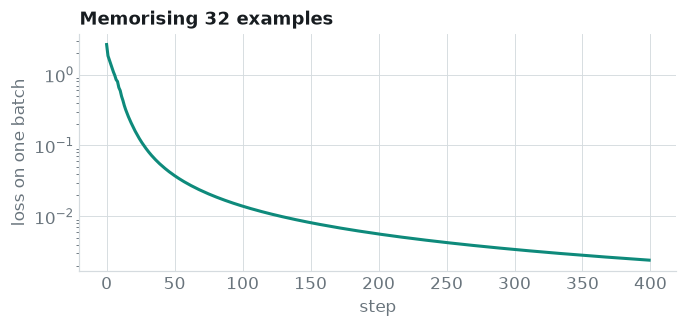

In [6]:
p = init(); xb, tb = X[tr[:32]], y[tr[:32]]; hist = []
for step in range(400):
    prob, cache = forward(p, xb); hist.append(loss_fn(prob, tb)); g = backward(p, prob, tb, cache)
    for k in p: p[k] -= 0.5 * g[k]
print(f"loss on the batch after 400 steps: {hist[-1]:.4f}   accuracy: {(prob.argmax(1) == tb).mean():.0%}")
plt.figure(figsize=(7, 2.8)); plt.semilogy(hist); plt.xlabel("step"); plt.ylabel("loss on one batch"); plt.title("Memorising 32 examples"); plt.show()

## The full loop

Now the real thing: mini-batches drawn at random, with the loss tracked on held-out data.

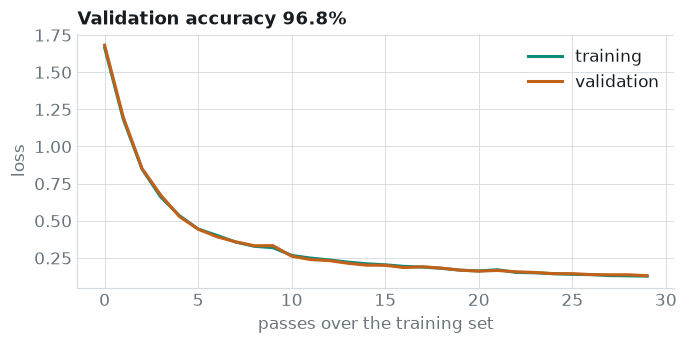

In [7]:
p = init(); train_hist, val_hist = [], []
for epoch in range(30):
    order = rng.permutation(tr)
    for i in range(0, len(order), 64):
        b = order[i:i + 64]; prob, cache = forward(p, X[b]); g = backward(p, prob, y[b], cache)
        for k in p: p[k] -= 0.1 * g[k]                             # the update: a small step against the gradient
    train_hist.append(loss_fn(forward(p, X[tr])[0], y[tr])); val_hist.append(loss_fn(forward(p, X[va])[0], y[va]))
acc = (forward(p, X[va])[0].argmax(1) == y[va]).mean()
plt.figure(figsize=(7, 3)); plt.plot(train_hist, label="training"); plt.plot(val_hist, label="validation")
plt.xlabel("passes over the training set"); plt.ylabel("loss"); plt.legend(); plt.title(f"Validation accuracy {acc:.1%}"); plt.show()

## Things to try

- Set the learning rate to 5.0, or to 0.0001, and watch what the curves do.
- Replace the careful initialisation with `r.normal(0, 1.0, ...)` and rerun check 2.
- Shuffle the labels (`y = rng.permutation(y)`) and confirm that validation accuracy falls to chance.